In [7]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline, make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score
import optuna
import cudf
import itertools

# Load the cuML acceleration extension
%load_ext cuml.accel

The cuml.accel extension is already loaded. To reload it, use:
  %reload_ext cuml.accel


In [8]:
from google.colab import files
uploaded = files.upload()

Saving test.csv to test.csv
Saving train.csv to train.csv


In [9]:
import io
import pandas as pd

# Get the list of uploaded filenames
file_names = list(uploaded.keys())

# Load the files
test_df = pd.read_csv(io.BytesIO(uploaded[file_names[0]]))
train_df = pd.read_csv(io.BytesIO(uploaded[file_names[1]]))

In [10]:
# No of rows in train data
train_len = len(train_df)

# Concatenate train and test data
df = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)

In [11]:
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12970 entries, 0 to 12969
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   12970 non-null  object 
 1   HomePlanet    12682 non-null  object 
 2   CryoSleep     12660 non-null  object 
 3   Cabin         12671 non-null  object 
 4   Destination   12696 non-null  object 
 5   Age           12700 non-null  float64
 6   VIP           12674 non-null  object 
 7   RoomService   12707 non-null  float64
 8   FoodCourt     12681 non-null  float64
 9   ShoppingMall  12664 non-null  float64
 10  Spa           12686 non-null  float64
 11  VRDeck        12702 non-null  float64
 12  Name          12676 non-null  object 
 13  Transported   8693 non-null   object 
dtypes: float64(6), object(8)
memory usage: 1.4+ MB


In [13]:
df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,12700.000000,12707.000000,12681.000000,12664.000000,12686.000000,12702.000000
mean,28.771969,222.897852,451.961675,174.906033,308.476904,306.789482
std,14.387261,647.596664,1584.370747,590.558690,1130.279641,1180.097223
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,49.000000,77.000000,29.000000,57.000000,42.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [14]:
df.describe(include=['O'])

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,VIP,Name,Transported
count,12970,12682,12660,12671,12696,12674,12676,8693
unique,12970,3,2,9825,3,2,12629,2
top,0001_01,Earth,False,G/734/S,TRAPPIST-1e,False,Artis Gambs,True
freq,1,6865,8079,8,8871,12401,2,4378


In [15]:
df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported'],
      dtype='object')

In [16]:
df["PassengerId"]

,PassengerId
0,0001_01
1,0002_01
2,0003_01
3,0003_02
4,0004_01
...,...
12965,9266_02
12966,9269_01
12967,9271_01
12968,9273_01


In [17]:
# Extract "GroupNo" from PassengerId column
df["GroupNo"] = df["PassengerId"].str.split(pat="_", expand=True)[0].astype(int)

In [18]:
df["GroupNo"]

,GroupNo
0,1
1,2
2,3
3,3
4,4
...,...
12965,9266
12966,9269
12967,9271
12968,9273


In [19]:
# Find the number of members in the specific passenger's group
df["GroupSize"] = df.groupby(["GroupNo"])["GroupNo"].transform("count")

In [20]:
df["GroupSize"]

,GroupSize
0,1
1,1
2,2
3,2
4,1
...,...
12965,2
12966,1
12967,1
12968,1


In [21]:
df.groupby(["GroupSize"], as_index=False)["Transported"].mean()

,GroupSize,Transported
0,1,0.452445
1,2,0.53805
2,3,0.593137
3,4,0.640777
4,5,0.592453
5,6,0.614943
6,7,0.541126
7,8,0.394231


In [22]:
# Divide group size into "Alone", "Small", "Medium" and "Large"
group_map = {1: "Alone", 2: "Small", 3: "Small", 4:"Small", 5: "Medium", 6: "Medium", 7: "Large", 8: "Large"}

df["GroupSize_grouped"] = df["GroupSize"].map(group_map)

In [23]:
df.groupby(["GroupSize_grouped"], as_index=False)["Transported"].mean()

,GroupSize_grouped,Transported
0,Alone,0.452445
1,Large,0.495522
2,Medium,0.601367
3,Small,0.569685


In [24]:
df.groupby(["HomePlanet"], as_index=False)["Transported"].mean()

,HomePlanet,Transported
0,Earth,0.423946
1,Europa,0.658846
2,Mars,0.523024


In [25]:
df.groupby(["CryoSleep"], as_index=False)["Transported"].mean()

,CryoSleep,Transported
0,False,0.328921
1,True,0.817583


In [26]:
df["CryoSleep"] = df["CryoSleep"].astype(float)

In [27]:
df.groupby(["Destination"], as_index=False)["Transported"].mean()

,Destination,Transported
0,55 Cancri e,0.61
1,PSO J318.5-22,0.503769
2,TRAPPIST-1e,0.471175


In [28]:
df["Cabin"].unique() #deck/num/side

array(['B/0/P', 'F/0/S', 'A/0/S', ..., 'D/296/P', 'D/297/P', 'G/1498/S'],
      shape=(9826,), dtype=object)

In [29]:
# Extract "Deck" from Cabin column
df["Deck"] = df["Cabin"].str.split(pat="/", expand=True)[0]

In [30]:
df["Deck"]

,Deck
0,B
1,F
2,A
3,A
4,F
...,...
12965,G
12966,NaN
12967,D
12968,D


In [31]:
df.groupby(["Deck"], as_index=False)["Transported"].mean()

,Deck,Transported
0,A,0.496094
1,B,0.734275
2,C,0.680054
3,D,0.433054
4,E,0.357306
5,F,0.439871
6,G,0.516217
7,T,0.2


In [32]:
# Extract "CabinNo" from Cabin column
df["CabinNo"] = df["Cabin"].str.split(pat="/", expand=True)[1]

In [33]:
df["CabinNo"]

,CabinNo
0,0
1,0
2,0
3,0
4,1
...,...
12965,1496
12966,NaN
12967,296
12968,297


In [34]:
df["CabinNo"] = pd.to_numeric(df["CabinNo"], errors="coerce")

In [35]:
# Extract "CabinSide" from Cabin column
df["CabinSide"] = df["Cabin"].str.split(pat="/", expand=True)[2]

In [36]:
df["CabinSide"]

,CabinSide
0,P
1,S
2,S
3,S
4,S
...,...
12965,S
12966,NaN
12967,P
12968,P


In [37]:
df.groupby(["CabinSide"], as_index=False)["Transported"].mean()

,CabinSide,Transported
0,P,0.45126
1,S,0.555037


In [38]:
df.groupby(["VIP"], as_index=False)["Transported"].mean()

,VIP,Transported
0,False,0.506332
1,True,0.38191


In [39]:
df["VIP"] = df["VIP"].astype(float)

In [40]:
# Create "MoneySpent" by adding all the expenses made by the passenger on RoomService, FoodCourt, ShoppingMall, Spa, VRDeck
df["MoneySpent"] = df["RoomService"] + df["FoodCourt"] + df["ShoppingMall"] + df["Spa"] + df["VRDeck"]

In [41]:
df["MoneySpent"]

,MoneySpent
0,0.0
1,736.0
2,10383.0
3,5176.0
4,1091.0
...,...
12965,0.0
12966,1018.0
12967,0.0
12968,3203.0


<Axes: >

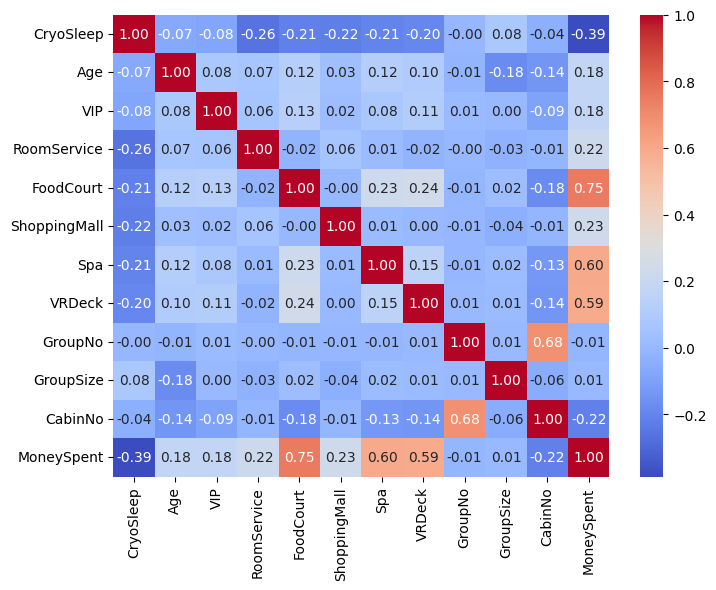

In [42]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")

In [43]:
train_df = df.iloc[:train_len].copy()
test_df = df.iloc[train_len:].copy()

In [44]:
X = train_df.drop(["PassengerId", "Cabin", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck", "Name", "GroupNo", "GroupSize", "Transported"], axis=1)
y = train_df["Transported"].astype(int)

X_test = test_df.drop(["PassengerId", "Cabin", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck", "Name", "GroupNo", "GroupSize"], axis=1)

In [45]:
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [46]:
ohe_cols = ["HomePlanet", "Destination", "Deck"]
ord_cols = ["CabinSide", "GroupSize_grouped"]
num_cols = ["Age", "MoneySpent", "CabinNo", "CryoSleep", "VIP"]

In [47]:
ohe_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("one-hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

In [48]:
ord_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
])

In [49]:
preprocessor = ColumnTransformer(
    transformers=[
        ("impute", SimpleImputer(strategy="median"), num_cols),
        ("ohe_pipeline", ohe_pipeline, ohe_cols),
        ("ord_pipeline", ord_pipeline, ord_cols),
    ],
    remainder="drop",
    n_jobs=-1
)

In [50]:
X_train_trans = preprocessor.fit_transform(X_train)
X_valid_trans = preprocessor.transform(X_valid)

In [51]:
X_train_gpu = cudf.DataFrame(X_train_trans).astype("float32")
y_train_gpu = cudf.Series(y_train).astype("int32")

X_valid_gpu = cudf.DataFrame(X_valid_trans).astype("float32")
y_valid_gpu = cudf.Series(y_valid).astype("int32")

In [52]:
X_test_trans = preprocessor.transform(X_test)
X_test_gpu = cudf.DataFrame(X_test_trans).astype("float32")

In [53]:
def objective_rfc(trial):
    n_estimators = trial.suggest_categorical("n_estimators", [150, 200, 300, 500])
    max_depth = trial.suggest_categorical("max_depth", [10, 13, 15, 17, 20])
    min_samples_split = trial.suggest_categorical("min_samples_split", [5, 10, 15])
    min_samples_leaf = trial.suggest_categorical("min_samples_leaf", [2, 4, 5, 6])

    # Extract raw numpy/cupy arrays to slice indices safely
    X_np = X_train_gpu.to_numpy() if hasattr(X_train_gpu, "to_numpy") else X_train_gpu
    y_np = y_train_gpu.to_numpy() if hasattr(y_train_gpu, "to_numpy") else y_train_gpu

    model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf)

    score = cross_val_score(model, X_np, y_np, cv=5, scoring="accuracy")

    return score.mean()

In [54]:
study_rfc = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler())

[I 2026-11-09 11:57:19,091] A new study created in memory with name: no-name-3c8e19f0-63bb-4725-b180-452b649dc15b


In [55]:
study_rfc.optimize(objective_rfc, n_trials=200)

/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [11:57:22] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.8.1
  warnings.warn(py_str(msg))
/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [11:57:23] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.8.1
  warnings.warn(py_str(msg))
/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [11:57:24] /__w/nvforest/nvforest/python/nvforest/

In [56]:
best_params_rfc = study_rfc.best_params

In [60]:
best_model_rfc = RandomForestClassifier(**best_params_rfc)

In [61]:
best_model_rfc.fit(X_train_gpu, y_train_gpu)

RandomForestClassifier(max_depth=17, min_samples_leaf=6, min_samples_split=5,
                       n_estimators=500)

In [62]:
y_pred_rfc = best_model_rfc.predict(X_valid_gpu)

/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [12:18:13] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.8.1
  warnings.warn(py_str(msg))


In [63]:
gpu_preds_rfc = best_model_rfc.predict(X_test_gpu)

In [64]:
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Transported": gpu_preds_rfc})
submission["Transported"] = submission["Transported"].astype(bool)
submission.to_csv("submission_rfc.csv", index=False)

In [65]:
def objective_knn(trial):
    n_neighbors = trial.suggest_categorical("n_neighbors", [3, 5, 7, 9, 11])
    weights = trial.suggest_categorical("weights", ['uniform', 'distance'])
    algorithm = trial.suggest_categorical("algorithm", ['auto', 'brute'])
    p = trial.suggest_categorical("p", [1, 2])

    # Extract raw numpy/cupy arrays to slice indices safely
    X_np = X_train_gpu.to_numpy() if hasattr(X_train_gpu, "to_numpy") else X_train_gpu
    y_np = y_train_gpu.to_numpy() if hasattr(y_train_gpu, "to_numpy") else y_train_gpu

    model = KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights, algorithm=algorithm, p=p)

    score = cross_val_score(model, X_np, y_np, cv=5, scoring="accuracy")

    return score.mean()

In [66]:
study_knn = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler())

[I 2026-11-09 12:18:24,846] A new study created in memory with name: no-name-841200c7-8c67-4cba-bf25-d343f68d68b2


In [67]:
study_knn.optimize(objective_knn, n_trials=200)

[I 2026-11-09 12:18:27,002] Trial 0 finished with value: 0.6540139333536766 and parameters: {'n_neighbors': 3, 'weights': 'distance', 'algorithm': 'brute', 'p': 1}. Best is trial 0 with value: 0.6540139333536766.
[I 2026-11-09 12:18:27,067] Trial 1 finished with value: 0.6499862942140895 and parameters: {'n_neighbors': 3, 'weights': 'distance', 'algorithm': 'auto', 'p': 2}. Best is trial 0 with value: 0.6540139333536766.
[I 2026-11-09 12:18:27,143] Trial 2 finished with value: 0.6814783629602429 and parameters: {'n_neighbors': 7, 'weights': 'distance', 'algorithm': 'brute', 'p': 1}. Best is trial 2 with value: 0.6814783629602429.
[I 2026-11-09 12:18:27,206] Trial 3 finished with value: 0.6626401998458745 and parameters: {'n_neighbors': 5, 'weights': 'distance', 'algorithm': 'auto', 'p': 2}. Best is trial 2 with value: 0.6814783629602429.
[I 2026-11-09 12:18:27,277] Trial 4 finished with value: 0.6934140854103202 and parameters: {'n_neighbors': 11, 'weights': 'distance', 'algorithm': 'a

In [68]:
best_params_knn = study_knn.best_params

In [70]:
best_model_knn = KNeighborsClassifier(**best_params_knn)

In [71]:
best_model_knn.fit(X_train_gpu, y_train_gpu)

KNeighborsClassifier(n_neighbors=11, p=1)

In [72]:
y_pred_knn = best_model_knn.predict(X_valid_gpu)

In [73]:
gpu_preds_knn = best_model_knn.predict(X_test_gpu)

In [74]:
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Transported": gpu_preds_knn})
submission["Transported"] = submission["Transported"].astype(bool)
submission.to_csv("submission_knn.csv", index=False)

In [75]:
def objective_lr(trial):
    C = trial.suggest_categorical("C", [100,10, 1.0, 0.1, 0.001, 0.001])

    # Extract raw numpy/cupy arrays to slice indices safely
    X_np = X_train_gpu.to_numpy() if hasattr(X_train_gpu, "to_numpy") else X_train_gpu
    y_np = y_train_gpu.to_numpy() if hasattr(y_train_gpu, "to_numpy") else y_train_gpu

    model = LogisticRegression(C=C)

    score = cross_val_score(model, X_np, y_np, cv=5, scoring="accuracy")

    return score.mean()

In [76]:
study_lr = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler())

[I 2026-11-09 12:19:00,927] A new study created in memory with name: no-name-a8858b87-39e7-4c31-86b6-10913ffa3c2a


In [77]:
study_lr.optimize(objective_lr, n_trials=200)

[2026-11-09 12:19:02.772] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:19:02.772] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:19:03.545] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:19:03.545] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:19:03.652] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:19:03.652] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.


[I 2026-11-09 12:19:03,837] Trial 0 finished with value: 0.7113889391721704 and parameters: {'C': 100}. Best is trial 0 with value: 0.7113889391721704.


[2026-11-09 12:19:03.831] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:19:03.831] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:19:03.944] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:19:03.944] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:19:04.048] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:19:04.048] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:19:04.155] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:19:04.155] [CUML] [warning] M

[I 2026-11-09 12:19:04,397] Trial 1 finished with value: 0.7076502076555866 and parameters: {'C': 0.001}. Best is trial 0 with value: 0.7113889391721704.


[2026-11-09 12:19:04.275] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:19:04.275] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:19:04.517] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:19:04.517] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:19:04.616] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:19:04.616] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:19:04.713] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:19:04.713] [CUML] [warning] M

[I 2026-11-09 12:19:04,920] Trial 2 finished with value: 0.7188664022053385 and parameters: {'C': 100}. Best is trial 2 with value: 0.7188664022053385.


... (391 outputs left out)

[I 2026-11-09 12:20:42,767] Trial 198 finished with value: 0.7067874155025369 and parameters: {'C': 0.001}. Best is trial 49 with value: 0.7244743960403209.


[2026-11-09 12:20:42.641] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:20:42.641] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:20:42.764] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:20:42.764] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:20:42.831] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:20:42.831] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.


[I 2026-11-09 12:20:43,068] Trial 199 finished with value: 0.7131085239644375 and parameters: {'C': 100}. Best is trial 49 with value: 0.7244743960403209.


[2026-11-09 12:20:42.892] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:20:42.892] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:20:42.950] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:20:42.950] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:20:43.008] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:20:43.008] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-09 12:20:43.065] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:20:43.065] [CUML] [warning] M

In [78]:
best_params_lr = study_lr.best_params

In [80]:
best_model_lr = LogisticRegression(**best_params_lr)

In [81]:
best_model_lr.fit(X_train_gpu, y_train_gpu)

[2026-11-09 12:20:43.274] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-09 12:20:43.275] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.


LogisticRegression()

In [82]:
y_pred_lr = best_model_lr.predict(X_valid_gpu)

In [83]:
gpu_preds_lr = best_model_lr.predict(X_test_gpu)

In [84]:
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Transported": gpu_preds_lr})
submission["Transported"] = submission["Transported"].astype(bool)
submission.to_csv("submission_lr.csv", index=False)

In [85]:
def objective_gnb(trial):
    var_smoothing = trial.suggest_categorical("var_smoothing", [0.00000001, 0.000000001, 0.00000001])

    # Extract raw numpy/cupy arrays to slice indices safely
    X_np = X_train_gpu.to_numpy() if hasattr(X_train_gpu, "to_numpy") else X_train_gpu
    y_np = y_train_gpu.to_numpy() if hasattr(y_train_gpu, "to_numpy") else y_train_gpu

    model = GaussianNB(var_smoothing=var_smoothing)

    score = cross_val_score(model, X_np, y_np, cv=5, scoring="accuracy")

    return score.mean()

In [86]:
study_gnb = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler())

[I 2026-11-09 12:20:43,325] A new study created in memory with name: no-name-83b7ded6-e142-4ef9-ab54-9d0de1e968fc


In [87]:
study_gnb.optimize(objective_gnb, n_trials=200)

[I 2026-11-09 12:20:43,364] Trial 0 finished with value: 0.7134021898225489 and parameters: {'var_smoothing': 1e-09}. Best is trial 0 with value: 0.7134021898225489.
[I 2026-11-09 12:20:43,393] Trial 1 finished with value: 0.7223170536180689 and parameters: {'var_smoothing': 1e-08}. Best is trial 1 with value: 0.7223170536180689.
[I 2026-11-09 12:20:43,421] Trial 2 finished with value: 0.7223170536180689 and parameters: {'var_smoothing': 1e-08}. Best is trial 1 with value: 0.7223170536180689.
[I 2026-11-09 12:20:43,450] Trial 3 finished with value: 0.7223170536180689 and parameters: {'var_smoothing': 1e-08}. Best is trial 1 with value: 0.7223170536180689.
[I 2026-11-09 12:20:43,478] Trial 4 finished with value: 0.7134021898225489 and parameters: {'var_smoothing': 1e-09}. Best is trial 1 with value: 0.7223170536180689.
[I 2026-11-09 12:20:43,505] Trial 5 finished with value: 0.7223170536180689 and parameters: {'var_smoothing': 1e-08}. Best is trial 1 with value: 0.7223170536180689.
[I 2

In [88]:
best_params_gnb = study_gnb.best_params

In [90]:
best_model_gnb = GaussianNB(**best_params_gnb)

In [93]:
# Convert preprocessed sparse/dense matrix to a standard NumPy array for Scikit-Learn
X_train_np = X_train_trans.toarray() if hasattr(X_train_trans, "toarray") else X_train_trans
y_train_np = y_train.to_numpy() if hasattr(y_train, "to_numpy") else np.array(y_train)

X_valid_np = X_valid_trans.toarray() if hasattr(X_valid_trans, "toarray") else X_valid_trans
X_test_np = X_test_trans.toarray() if hasattr(X_test_trans, "toarray") else X_test_trans

# Fit and predict using standard NumPy arrays
best_model_gnb.fit(X_train_np, y_train_np)

GaussianNB(var_smoothing=1e-08)

In [95]:
y_pred_gnb = best_model_gnb.predict(X_valid_np)

In [97]:
gpu_preds_gnb = best_model_gnb.predict(X_test_np)

In [98]:
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Transported": gpu_preds_gnb})
submission["Transported"] = submission["Transported"].astype(bool)
submission.to_csv("submission_gnb.csv", index=False)

In [99]:
def objective_xgb(trial):
    X_train_trans = preprocessor.fit_transform(X_train)
    if hasattr(X_train_trans, "toarray"):
        X_train_trans = X_train_trans.toarray()
    y_train_np = y_train.to_numpy() if hasattr(y_train, "to_numpy") else np.array(y_train)

    n_estimators = trial.suggest_categorical("n_estimators", [100, 200])
    max_depth = trial.suggest_categorical("max_depth", [3, 5, 7])
    learning_rate = trial.suggest_categorical("learning_rate", [0.01, 0.1, 0.2])
    subsample = trial.suggest_categorical("subsample", [0.8, 1.0])

    # Extract raw numpy/cupy arrays to slice indices safely
    X_np = X_train_gpu.to_numpy() if hasattr(X_train_gpu, "to_numpy") else X_train_gpu
    y_np = y_train_gpu.to_numpy() if hasattr(y_train_gpu, "to_numpy") else y_train_gpu

    model = XGBClassifier(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate, subsample=subsample, device="cuda")

    score = cross_val_score(model, X_np, y_np, cv=5, scoring="accuracy", n_jobs=-1)

    return score.mean()

In [100]:
study_xgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler())

[I 2026-11-09 12:29:09,734] A new study created in memory with name: no-name-10f8a35b-fd8f-4a42-a26a-6348ed642732


In [101]:
study_xgb.optimize(objective_xgb, n_trials=200)

[I 2026-11-09 12:29:17,488] Trial 0 finished with value: 0.7568315326171844 and parameters: {'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.1, 'subsample': 1.0}. Best is trial 0 with value: 0.7568315326171844.
[I 2026-11-09 12:29:20,637] Trial 1 finished with value: 0.7510793435704348 and parameters: {'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.01, 'subsample': 1.0}. Best is trial 0 with value: 0.7568315326171844.
[I 2026-11-09 12:29:22,500] Trial 2 finished with value: 0.7402961484155595 and parameters: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.2, 'subsample': 1.0}. Best is trial 0 with value: 0.7568315326171844.
[I 2026-11-09 12:29:24,144] Trial 3 finished with value: 0.7482049558053054 and parameters: {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.2, 'subsample': 0.8}. Best is trial 0 with value: 0.7568315326171844.
[I 2026-11-09 12:29:26,226] Trial 4 finished with value: 0.7372753932008957 and parameters: {'n_estimators': 200, 'max_dept

In [102]:
best_params_xgb = study_xgb.best_params

In [103]:
best_model_xgb = XGBClassifier(**best_params_xgb, device="cuda")

In [104]:
best_model_xgb.fit(X_train_gpu, y_train_gpu)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [105]:
y_pred_xgb = best_model_xgb.predict(X_valid_gpu)

In [106]:
gpu_preds_xgb = best_model_xgb.predict(X_test_gpu)

In [107]:
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Transported": gpu_preds_xgb})
submission["Transported"] = submission["Transported"].astype(bool)
submission.to_csv("submission_xgb.csv", index=False)